# Ablation of k-nearest neighbors in clustering

Effects of changing the $k$ in $k$-nearest neighbor graph construction performed prior to Leiden clustering.

In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='neighbor_k', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [4]:
ordered_metrics = [
    'MCC', 'F1', 'JACC', 'PURITY', 'HOMO', 'CCENT', # Cluster-as-prediction
    'COMP', # Joint bio&batch
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'CLUSTASW', 'CLUSTCH', 'CLUSTDBI', 'MODULARITY', 'COMPACT', 'SEPARATION', # Independent cluster metrics
    'BATCHARI', 'BCENT', 'BP', 'CRE'
]

batch_metrics = ['BATCHARI', 'BCENT', 'BP', 'CRE']

In [5]:
def test_k1_k2(df_metric, k1, k2):
    k15 = df_metric[df_metric['neighbor_k'] == k1].set_index('Integration')['Value']
    k20 = df_metric[df_metric['neighbor_k'] == k2].set_index('Integration')['Value']
    
    # Align on Integration
    common = k15.index.intersection(k20.index)
    k15 = k15.loc[common]
    k20 = k20.loc[common]
    
    if len(common) < 3:
        return pd.Series({'statistic': np.nan, 'p_value': np.nan, 'direction': np.nan})
    
    diff = k20 - k15
    mean_diff = diff.mean()

    stat, p = wilcoxon(k15, k20, alternative='two-sided')
    
    return pd.Series({
        'statistic': stat,
        'p_value': p,
        'mean_diff': mean_diff,
        'direction': 'increase' if mean_diff > 0 else 'decrease'
    })

## Collect the data from the eight different datasets

The combined metric file is available as `robustness_neighbor_k_leiden.csv`. To reproduce the Kendall's W, instead of using the code to load the CSV files, instead subset the metric file to the given dataset. e.g.

```Python
df_full = pd.read_csv('../data/source_data/robustness_neighbor_k_leiden.csv')
df_sub = df_full[df_full['Dataset'] == 'neurips_bmmc']
```

### NeurIPS BMMC data

In [6]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_neurips_bmmc/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_neurips_bmmc_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)
df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel()

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [7]:
w_results_1 = compute_w_across_integrations(df_sub)
w_results_1['Dataset'] = "neurips_bmmc"
w_results_1

,Metric,Kendall_W,Dataset
0,AMI,0.980199,neurips_bmmc
1,ARI,0.894016,neurips_bmmc
2,AWC,0.900180,neurips_bmmc
3,BAMI,0.996036,neurips_bmmc
4,BARI,0.978018,neurips_bmmc
5,BATCHARI,0.947330,neurips_bmmc
6,BCENT,0.954557,neurips_bmmc
7,BP,0.925195,neurips_bmmc
8,BVM,0.996339,neurips_bmmc
9,CCENT,0.995107,neurips_bmmc


In [8]:
df_1 = df_sub.copy()

### scIB sim1

In [9]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_scib_sim1/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_scib_sim1_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [10]:
w_results_2 = compute_w_across_integrations(df_sub)
w_results_2['Dataset'] = "scib_sim1"
w_results_2

,Metric,Kendall_W,Dataset
0,AMI,0.974097,scib_sim1
1,ARI,0.965002,scib_sim1
2,AWC,0.965716,scib_sim1
3,BAMI,0.995601,scib_sim1
4,BARI,0.993966,scib_sim1
5,BATCHARI,0.980159,scib_sim1
6,BCENT,0.971535,scib_sim1
7,BP,0.946191,scib_sim1
8,BVM,0.995601,scib_sim1
9,CCENT,0.999450,scib_sim1


In [11]:
df_2 = df_sub.copy()

### Mouse mammary

In [12]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_mouse_mammary/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_mouse_mammary_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [13]:
w_results_3 = compute_w_across_integrations(df_sub)
w_results_3['Dataset'] = "mouse_mammary"
w_results_3

,Metric,Kendall_W,Dataset
0,AMI,0.957713,mouse_mammary
1,ARI,0.953192,mouse_mammary
2,AWC,0.954403,mouse_mammary
3,BAMI,0.942799,mouse_mammary
4,BARI,0.945041,mouse_mammary
5,BATCHARI,0.983377,mouse_mammary
6,BCENT,0.945539,mouse_mammary
7,BP,0.888061,mouse_mammary
8,BVM,0.942799,mouse_mammary
9,CCENT,0.959884,mouse_mammary


In [14]:
df_3 = df_sub.copy()

### Human Pancreas

In [15]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pancreas/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pancreas_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

# Handle cases where num_metrics might be less than NUM_COLS or rows=1
if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [16]:
w_results_4 = compute_w_across_integrations(df_sub)
w_results_4['Dataset'] = "human_pancreas"
w_results_4

,Metric,Kendall_W,Dataset
0,AMI,0.993231,human_pancreas
1,ARI,0.988243,human_pancreas
2,AWC,0.988162,human_pancreas
3,BAMI,0.993231,human_pancreas
4,BARI,0.989506,human_pancreas
5,BATCHARI,0.943595,human_pancreas
6,BCENT,0.974672,human_pancreas
7,BP,0.958713,human_pancreas
8,BVM,0.992842,human_pancreas
9,CCENT,0.997976,human_pancreas


In [17]:
df_4 = df_sub.copy()

### Human pbmc seq techs

In [18]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_human_pbmc_seq_techs/metrics/all-metrics.csv')

df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [19]:
w_results_5 = compute_w_across_integrations(df_sub)
w_results_5['Dataset'] = "human_pbmc_seq_techs"
w_results_5

,Metric,Kendall_W,Dataset
0,AMI,0.987501,human_pbmc_seq_techs
1,ARI,0.984288,human_pbmc_seq_techs
2,AWC,0.981570,human_pbmc_seq_techs
3,BAMI,0.993286,human_pbmc_seq_techs
4,BARI,0.992071,human_pbmc_seq_techs
5,BATCHARI,0.933982,human_pbmc_seq_techs
6,BCENT,0.947614,human_pbmc_seq_techs
7,BP,0.961989,human_pbmc_seq_techs
8,BVM,0.993286,human_pbmc_seq_techs
9,CCENT,0.993946,human_pbmc_seq_techs


In [20]:
df_5 = df_sub.copy()

### Seurat PBMC

In [21]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_seurat_pbmc/metrics/all-metrics.csv')
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [22]:
w_results_6 = compute_w_across_integrations(df_sub)
w_results_6['Dataset'] = "seurat_pbmc"
w_results_6

,Metric,Kendall_W,Dataset
0,AMI,0.976539,seurat_pbmc
1,ARI,0.969294,seurat_pbmc
2,AWC,0.978587,seurat_pbmc
3,BAMI,0.995789,seurat_pbmc
4,BARI,0.991920,seurat_pbmc
5,BATCHARI,0.968762,seurat_pbmc
6,BCENT,0.970716,seurat_pbmc
7,BP,0.969369,seurat_pbmc
8,BVM,0.995789,seurat_pbmc
9,CCENT,0.990858,seurat_pbmc


In [23]:
df_6 = df_sub.copy()

### Cellranger versions

In [24]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_cellranger_versions/metrics/all-metrics.csv')
df2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_cellranger_versions_rescue/metrics/all-metrics.csv')
df = pd.concat([df, df2])
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [25]:
w_results_7 = compute_w_across_integrations(df_sub)
w_results_7['Dataset'] = "cellranger_versions"
w_results_7

,Metric,Kendall_W,Dataset
0,AMI,0.954101,cellranger_versions
1,ARI,0.939009,cellranger_versions
2,AWC,0.943141,cellranger_versions
3,BAMI,0.983603,cellranger_versions
4,BARI,0.976267,cellranger_versions
5,BATCHARI,0.960564,cellranger_versions
6,BCENT,0.975199,cellranger_versions
7,BP,0.976503,cellranger_versions
8,BVM,0.983796,cellranger_versions
9,CCENT,0.979812,cellranger_versions


In [26]:
df_7 = df_sub.copy()

### NPH Cerebellum

In [27]:
df = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/clustering_ablation/leiden_nph_cerebellum/metrics/all-metrics.csv')
df = df.drop_duplicates(
    subset=["Integration", "Metric", "neighbor_k", "neighbor_type", "Dataset"],keep='first'  # Keep last means the most recent result will be stored.
)
df['Integration'] = df['Integration'].str[:-2]
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH',
    'CBE': 'CRE',
    'BPS': 'BP'
})
df = df[~df.Value.isna()]
df = df[df['Metric'] != 'CLUSTACC']
df_sub = df[df.neighbor_type == 'default']

In [ ]:
label_order = [5, 10, 15, 20, 25]
df_sub['neighbor_k'] = pd.Categorical(df_sub['neighbor_k'], categories=label_order, ordered=True)

df_sub['Rank'] = df_sub.groupby(['Metric', 'neighbor_k'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 6
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = 7.3
fig_height = num_rows * 2
fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height), sharey=True)
fig.patch.set_alpha(0.0)

if num_rows == 1 and NUM_COLS == 1:
    axes = [axes]
elif num_rows == 1 or NUM_COLS == 1:
    axes = axes.flatten()
else:
    axes = axes.ravel() # Flatten for easier iteration

unique_integrations = df_sub['Integration'].unique()
color_map =  palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

for i, metric in enumerate(metrics):
    ax = axes[i]
    subset = df_sub[df_sub['Metric'] == metric]
    
    sns.lineplot(
        data=subset,
        x='neighbor_k',
        y='Rank',
        hue='Integration',
        marker='o',
        markeredgewidth=0,
        markersize=2,
        linewidth=0.5, 
        palette=color_map, 
        ax=ax
    )
    ax.set_facecolor('white')
    ax.patch.set_alpha(1.0)
    ax.set_title(metric, fontsize=5, pad=2)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    ax.set_xticks([5, 10, 15, 20, 25])

    if i % NUM_COLS == 0:
        ax.set_ylabel('Rank', fontsize=5)
    else:
        ax.set_ylabel('')
    
    if len(metrics) >= i >= len(metrics) - NUM_COLS:
        ax.set_xlabel('# neighbors', fontsize=5)
    else:
        ax.set_xlabel('')
    ax.get_legend().remove()

for j in range(num_metrics, num_rows * NUM_COLS):
    fig.delaxes(axes[j])

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles, 
    labels, 
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.08),
    ncol=min(len(unique_integrations), 8),
    fontsize=5,
    title="",
    frameon=False
)

axes[0].invert_yaxis()
plt.show()

In [28]:
w_results_8 = compute_w_across_integrations(df_sub)
w_results_8['Dataset'] = "nph_cerebellum"
w_results_8

,Metric,Kendall_W,Dataset
0,AMI,0.934968,nph_cerebellum
1,ARI,0.926710,nph_cerebellum
2,AWC,0.923581,nph_cerebellum
3,BAMI,0.947065,nph_cerebellum
4,BARI,0.948806,nph_cerebellum
5,BATCHARI,0.826065,nph_cerebellum
6,BCENT,0.968194,nph_cerebellum
7,BP,0.926380,nph_cerebellum
8,BVM,0.947065,nph_cerebellum
9,CCENT,0.983968,nph_cerebellum


In [29]:
df_8 = df_sub.copy()

## Plot Kendall's W

In [30]:
w_results = pd.concat([w_results_1, w_results_2, w_results_3, w_results_4, w_results_5, w_results_6, w_results_7, w_results_8])
w_results.reset_index(drop=True, inplace=True)

In [31]:
# Produced by ablation_analysis_leiden_seed.ipynb
control = pd.read_csv('../results/spreadsheets/leiden_seed_W.csv', index_col=0)

In [32]:
merged = w_results.merge(control, on=['Metric', 'Dataset'], how='left', suffixes=('_data', '_control'))
merged['diff_W'] = merged['Kendall_W_data'] - merged['Kendall_W_control']
merged['prop_W'] = merged['Kendall_W_data'] / merged['Kendall_W_control']

/tmp/ipykernel_3275107/361650429.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


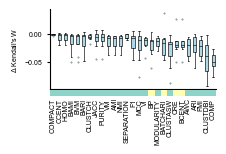

In [33]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import FancyBboxPatch

order = merged.groupby("Metric")["diff_W"].median().sort_values(ascending=False).index
g0 = 'Bioconservation'
g1 = 'Batch correction'
g2 = 'Joint'
metric_to_group = {
    'fmi': g0, 'awc': g0, 'ari': g0, 'vi': g0, 'nmi': g0, 'ami': g0, 'vm':g0, 
    'bari': g0, 'bami': g0, 'bvm': g0, 
    'isoasw': g0, 'gc': g2, 'isof1': g0, 'isolisi': g0,
    'casw': g0, 'cdbi': g0, 'cch': g0, 
    'blogreg': g2, 'flogreg': g0, 
    'clisi': g0, 'fknn': g0, 'ksim': g0, 'ocs': g0, 'nnmap': g0, 'cnent': g0, 
    'cnentropyw': g0, 'bknn': g2, 'f1': g0, 'mcc': g0, 'jacc': g0, 'purity': g0, 
    'ccent': g0, 'homo': g0, 'arif': g0, 'nmif': g0, 
    'clustch': g0, 'clustasw': g0, 'clustdbi': g0, 
    'comp': g0, 'pptpc': g2, 'pstdb': g2, 
    'ldfdiff': g0, 'agree': g0, 'morani': g0, 'rknn': g0, 'ccc': g0, 
    'scgraph': g0, 'corrmse': g0, 'traj': g0, 'scgraphp': g0, 'scgraphm': g0,
    'modularity': g0, 'compact': g0, 'separation': g0,
    'mix': g1, 'align': g1, 'ilisi': g1, 'bnent': g1, 'kldiv': g1,
    'adgbd': g1, 'kbetall': g1, 'cilisi': g1, 'csms': g1, 'kbet': g1,
    'bras': g1, 'embdiv': g1, 'probe': g1, 'batchari': g1, 'pcr': g1,
    'probelr': g1, 'proberf': g1,
    'bp': g1, 'bcent': g1, 'cre': g1,
    'basw': g1, 'sv': g1,
}
group_to_color = {
    g0: '#8dd3c7', g1: '#ffffb3', g2: '#bebada'
}
boxplot_data = [merged[merged["Metric"] == metric]["diff_W"].values for metric in order]

fig, ax = plt.subplots(figsize=(2.4, 1.1))

ax.boxplot(
    boxplot_data, 
    labels=order,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", color="black", linewidth=.45),
    medianprops=dict(color="black", linewidth=.45),
    whiskerprops=dict(color="black", linewidth=.45),
    capprops=dict(color="black", linewidth=.45),
    flierprops=dict(marker="o", markerfacecolor="lightblue", markersize=.95, markeredgecolor='gray', markeredgewidth=0.4)
)
ax.tick_params(axis='both', labelsize=5, length=2)
ax.tick_params(axis='x', length=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylabel("$\\Delta$ Kendall's W", fontsize=5)
ax.set_xticklabels([])

plt.tight_layout()
fig.canvas.draw()

# --- sizing in points ---
box_h_pt   = 4    # height of each color box
box_w_pt   = 18   # width of each color box (adjust to taste)
gap_pt     = 0.6    # gap between tick line and box top

# Convert points to display units
dpi        = fig.dpi
pt_to_disp = dpi / 72.0

# Transform: x in data coords, y pinned to axes bottom in display coords
trans = ax.transData

if len(order) > 1:
    x0_disp = ax.transData.transform((1, ax.get_ylim()[0]))[0]
    x1_disp = ax.transData.transform((2, ax.get_ylim()[0]))[0]
    tick_spacing_disp = x1_disp - x0_disp
else:
    tick_spacing_disp = 20 * pt_to_disp

box_w_disp = tick_spacing_disp * 1  # 85% of spacing, leaving a small gap between boxes

for i, metric in enumerate(order):
    tick_x = i + 1
    grp    = metric_to_group.get(metric.lower(), "Unknown")
    color  = group_to_color.get(grp, "gray")

    x_disp, y_disp = ax.transData.transform((tick_x, ax.get_ylim()[0]))

    box_top    = y_disp - gap_pt * pt_to_disp
    box_bottom = box_top - box_h_pt * pt_to_disp
    box_left   = x_disp - box_w_disp / 2
    box_right  = x_disp + box_w_disp / 2

    inv = ax.transAxes.inverted()
    xl, yt = inv.transform((box_left,  box_top))
    xr, yb = inv.transform((box_right, box_bottom))

    rect = FancyBboxPatch(
        (xl, yb), xr - xl, yt - yb,
        boxstyle="square,pad=0",   # no rounding — boxes are tiny at this scale
        transform=ax.transAxes,
        clip_on=False,
        facecolor=color,
        edgecolor="none",
        zorder=5,
    )
    ax.add_patch(rect)

    inv = ax.transAxes.inverted()
    lx, ly = inv.transform((x_disp, box_bottom - 2 * pt_to_disp))
    ax.text(
        lx, ly, metric,
        transform=ax.transAxes,
        ha='center', va='top',
        fontsize=5,
        rotation=90,
        clip_on=False,
    )
# plt.savefig('../publication_figures/clustering_neighbor_k_W.svg', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
merged.groupby("Metric")["diff_W"].mean().sort_values()

Metric
COMP         -0.049027
CLUSTDBI     -0.042861
CLUSTASW     -0.030620
FMI          -0.024274
AWC          -0.023863
ARI          -0.023045
BP           -0.021367
MCC          -0.020958
BCENT        -0.017438
CRE          -0.017438
BATCHARI     -0.017127
VI           -0.016273
F1           -0.015952
MODULARITY   -0.015385
BARI         -0.014431
BVM          -0.014232
BAMI         -0.014170
AMI          -0.013696
VM           -0.013568
NMI          -0.013568
PURITY       -0.010709
JACC         -0.010709
CLUSTCH      -0.006525
HOMO         -0.006000
CCENT        -0.005909
SEPARATION   -0.005829
COMPACT      -0.001495
Name: diff_W, dtype: float64

In [35]:
merged.groupby("Metric")["prop_W"].mean().sort_values()

Metric
COMP          0.949961
CLUSTDBI      0.955908
CLUSTASW      0.966990
FMI           0.974979
AWC           0.975478
ARI           0.976286
BP            0.977926
MCC           0.978865
BCENT         0.982493
CRE           0.982494
VI            0.983460
BATCHARI      0.983725
F1            0.983918
MODULARITY    0.984590
BARI          0.985461
BVM           0.985651
BAMI          0.985714
AMI           0.986091
VM            0.986221
NMI           0.986221
PURITY        0.989202
JACC          0.989202
CLUSTCH       0.993459
HOMO          0.993931
CCENT         0.994022
SEPARATION    0.994169
COMPACT       0.998505
Name: prop_W, dtype: float64

In [36]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('BARI', 'ARI'),
    ('BAMI', 'AMI'),
    ('BVM', 'VM')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(142.0), pvalue=np.float64(0.8191748326849633))

In [37]:
df_wide = merged.pivot_table(index='Dataset', columns='Metric', values="diff_W", aggfunc='mean')
pairs = [
    ('AMI', 'ARI'),
    ('BAMI', 'BARI')
]

l = []
for m1, m2 in pairs:
    l.append(df_wide[[m1, m2]].to_numpy())
l = np.concatenate(l)
wilcoxon(l[:, 0], l[:, 1])

WilcoxonResult(statistic=np.float64(35.0), pvalue=np.float64(0.09344482421875))

## Differences in coefficient of variation

In [30]:
df_full = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8])
df_full = df_full[df_full.Metric != 'ISOF1']
df_full.replace([np.inf, -np.inf], np.nan, inplace=True)

In [32]:
df_full.to_csv('../results/spreadsheets/ablation_neighbor_k_leiden.csv', index=False)

In [39]:
cvs = df_full.pivot(index=['Dataset', 'Integration', 'neighbor_k'],
                    columns='Metric', values="Value").groupby(['Dataset', 'neighbor_k'])[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()

In [40]:
def plot_cv_metrics(
    df: pd.DataFrame,
    dataset_col: str = "Dataset",
    k_col: str = "neighbor_k",
    reference_k: int = 15,
    ncols: int = 6,
    figsize_per_cell: tuple = (1.1, 1),
    alpha_levels: tuple = (0.05, 0.01, 0.001),
    color: str = "#378ADD",
    adjustment_method: str = "fdr_bh",
):
    """
    Plot small-multiple line charts of coefficient of variation (CV) vs neighbor_k,
    averaged across datasets, with Wilcoxon signed-rank significance stars
    compared to a reference k value.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain `dataset_col`, `k_col`, and one column per metric.
    dataset_col : str
        Column name identifying datasets.
    k_col : str
        Column name for neighbor_k values.
    reference_k : int
        The k value to test significance against (default 15).
    ncols : int
        Number of columns in the small-multiple grid.
    figsize_per_cell : tuple
        (width, height) in inches for each subplot cell.
    alpha_levels : tuple
        Thresholds for *, **, *** significance (default 0.05, 0.01, 0.001).
    color : str
        Line/marker color.
    """
    import matplotlib.ticker as mticker
    from scipy.stats import wilcoxon
    metric_cols = ordered_metrics
    k_values = sorted(df[k_col].unique())
    n_metrics = len(metric_cols)
    nrows = math.ceil(n_metrics / ncols)
 
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(figsize_per_cell[0] * ncols, figsize_per_cell[1] * nrows),
        constrained_layout=True,
    )
    axes_flat = np.array(axes).flatten()
 
    ref_data = {}
    for metric in metric_cols:
        ref_subset = df[df[k_col] == reference_k][metric].dropna().values
        ref_data[metric] = ref_subset
        
    raw_p_values = {}
    means_per_metric = {}
    stderrs_per_metric = {}
 
    for metric in metric_cols:
        means, stderrs = [], []
        for k in k_values:
            vals = df[df[k_col] == k][metric].dropna().values
            means.append(np.mean(vals))
            stderrs.append(np.std(vals, ddof=1) / np.sqrt(len(vals)))
 
            if k != reference_k and len(vals) >= 2 and len(ref_data[metric]) >= 2:
                ref_vals = ref_data[metric]
                min_len = min(len(vals), len(ref_vals))
                diffs = vals[:min_len] - ref_vals[:min_len]
                if np.any(diffs != 0):
                    _, p = wilcoxon(diffs)
                else:
                    p = 1.0
                raw_p_values[(metric, k)] = p
 
        means_per_metric[metric] = np.array(means)
        stderrs_per_metric[metric] = np.array(stderrs)
        
    keys = list(raw_p_values.keys())
    raw_p_array = np.array([raw_p_values[k] for k in keys])
    _, adj_p_array, _, _ = multipletests(raw_p_array, method=adjustment_method)
    adj_p_values = dict(zip(keys, adj_p_array))
 
    for idx, metric in enumerate(metric_cols):
        ax = axes_flat[idx]
        means = means_per_metric[metric]
        stderrs = stderrs_per_metric[metric]
 
        ax.plot(k_values, means, color=color, linewidth=.45, zorder=3,
                marker="o", markersize=2, markerfacecolor="white",
                markeredgecolor=color, markeredgewidth=.45)

 
        ax.axvline(reference_k, color="#888780", linewidth=1,
                   linestyle="--", zorder=1, alpha=0.7)
 
        y_range = ax.get_ylim()[1] - ax.get_ylim()[0]
        point_offset = y_range * 0.04
        
        point_offset = y_range * 0.04
        for i, k in enumerate(k_values):
            if k == reference_k or (metric, k) not in adj_p_values:
                continue
            p = adj_p_values[(metric, k)]
            if p < alpha_levels[2]:
                stars = "***"
            elif p < alpha_levels[1]:
                stars = "**"
            elif p < alpha_levels[0]:
                stars = "*"
            else:
                stars = "ns"
 
            if stars != "ns":
                point_y = means[k_values.index(k)]
                ax.text(k, point_y + point_offset, stars, ha="center", va="bottom",
                        fontsize=9, color="#D85A30", fontweight="bold",
                        clip_on=False)
 
        ax.set_title(metric, fontsize=5, fontweight="medium", pad=6)
        last_row_start = (nrows - 1) * ncols
        is_bottom = last_row_start <= idx < last_row_start + ncols and idx < n_metrics
        is_left = idx % ncols == 0
        if is_bottom:
            ax.set_xlabel("k", fontsize=5)
        if is_left:
            ax.set_ylabel("CV", fontsize=5)
        ax.set_xticks(k_values)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        ax.set_xlim(3, 27)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(0.45)
        ax.spines["bottom"].set_linewidth(0.45)
#         ticks = ax.yaxis.get_majorticklocs()
#         fmt = "%.2f" if all(round(t, 2) == round(t, 3) for t in ticks) else "%.3f"
#         ax.yaxis.set_major_formatter(mticker.FormatStrFormatter(fmt))
 
    for idx in range(n_metrics, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    return fig

/tmp/ipykernel_3275107/569818097.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


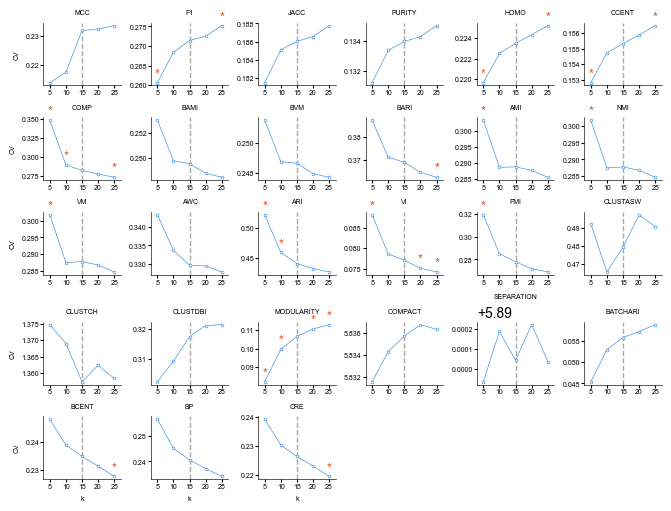

In [41]:
fig = plot_cv_metrics(cvs)
# fig.savefig('../publication_figures/leiden_clustering_neighbor_k_cvs.png', dpi=300, bbox_inches='tight')
fig.show()